Cell 1 Downloads libraries from the Materials Project,giving the project suffiecient and powerful tools to proceed

In [2]:
%pip install mp-api matminer

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 MB 73.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 73.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 52.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 120.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 106.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.7/829.7 kB 38.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 93.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 63.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 979.1/979.1 kB 36.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.2/16.2 MB 107.4 MB/s  0:00:00
  Created wheel for bibtexparser: filename=bibtexparser-1.4.4-py3-none-any.whl size=43686 sha256=65eb8f8c792

downloads every stable, non-metallic compound with 2 to 4 elements from the Materials Project and organize their band gaps and stability into a table

In [3]:
from getpass import getpass
from mp_api.client import MPRester
import pandas as pd

API_KEY = getpass("Paste your Materials Project API key: ")

with MPRester(API_KEY) as mpr:
    docs = mpr.materials.summary.search(
        is_stable=True,
        band_gap=(0.01, None),
        num_elements=(2, 4),
        fields=["material_id", "formula_pretty", "band_gap",
                "is_gap_direct", "energy_above_hull"],
    )

df = pd.DataFrame([{
    "material_id": str(d.material_id),
    "formula": d.formula_pretty,
    "band_gap": d.band_gap,
    "is_gap_direct": d.is_gap_direct,
    "energy_above_hull": d.energy_above_hull,
} for d in docs])
df.to_csv("raw_data.csv", index=False)
print(f"Downloaded {len(df)} stable semiconductors and insulators")
df.head()

Paste your Materials Project API key: ··········


Output()

✓ Retrieved 14,527 SummaryDoc documents in 16.5s

Downloaded 14527 stable semiconductors and insulators


,material_id,formula,band_gap,is_gap_direct,energy_above_hull
0,mp-11107,Ac2O3,3.5219,False,0.0
1,mp-32800,Ac2S3,2.2729,False,0.0
2,mp-1183115,AcAlO3,4.1024,True,0.0
3,mp-27972,AcBr3,4.1034,False,0.0
4,mp-30274,AcBrO,4.2407,True,0.0


keeps only one entry per formula

In [5]:
df = (df.sort_values("energy_above_hull")
        .drop_duplicates(subset="formula", keep="first")
        .reset_index(drop=True))
print(f"Unique compounds after removing duplicates: {len(df)}")

Unique compounds after removing duplicates: 14467


Describes each compound with 132 numbers based on its elements such asaverage electronegativity, atomic size, etc

In [6]:
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty

df["composition"] = df["formula"].apply(Composition)
featurizer = ElementProperty.from_preset("magpie")
df = featurizer.featurize_dataframe(df, col_id="composition", ignore_errors=True)
feature_cols = featurizer.feature_labels()
df = df.dropna(subset=feature_cols).reset_index(drop=True)
print(f"{len(feature_cols)} features for {len(df)} compounds")

ElementProperty:   0%|          | 0/14467 [00:00<?, ?it/s]

132 features for 14467 compounds


Trains a random forest and measures how well it predicts band gaps it has never seen.

In [7]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score

X = df[feature_cols]
y = df["band_gap"]
model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

df["predicted_gap"] = cross_val_predict(model, X, y, cv=cv)
mae = mean_absolute_error(y, df["predicted_gap"])
r2 = r2_score(y, df["predicted_gap"])
baseline = mean_absolute_error(y, np.full(len(y), y.mean()))
print(f"MAE: {mae:.2f} eV   R2: {r2:.2f}")
print(f"Baseline MAE (always guess the average): {baseline:.2f} eV")

MAE: 0.46 eV   R2: 0.83
Baseline MAE (always guess the average): 1.34 eV


Dots on the dashed line are perfect predictions.

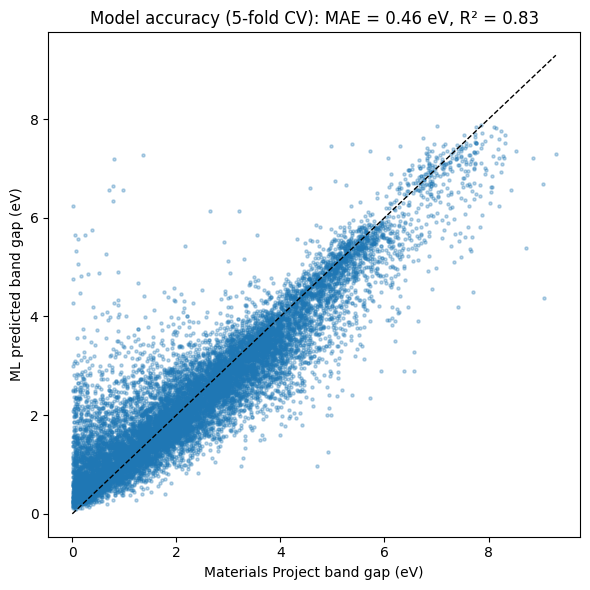

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y, df["predicted_gap"], s=5, alpha=0.3)
lim = [0, max(y.max(), df["predicted_gap"].max())]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("Materials Project band gap (eV)")
ax.set_ylabel("ML predicted band gap (eV)")
ax.set_title(f"Model accuracy (5-fold CV): MAE = {mae:.2f} eV, R² = {r2:.2f}")
plt.tight_layout()
plt.savefig("fig1_parity.png", dpi=200)
plt.show()

Big electronegativity differences mean more ionic bonds, which usually means bigger band gaps as seen in table

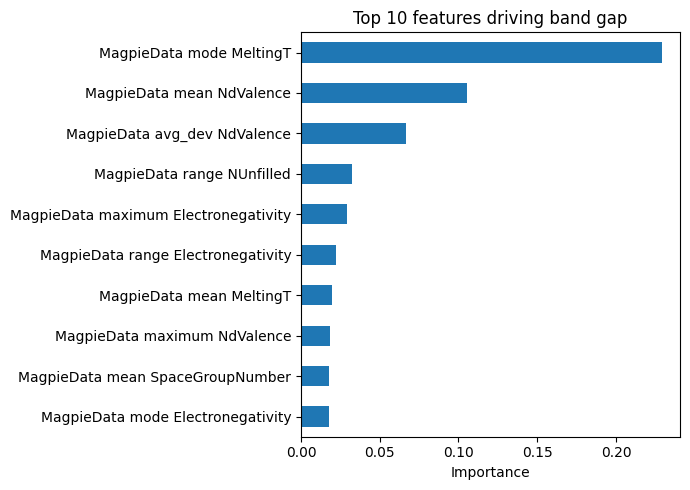

MagpieData mode MeltingT                0.229188
MagpieData mean NdValence               0.105672
MagpieData avg_dev NdValence            0.066647
MagpieData range NUnfilled              0.032204
MagpieData maximum Electronegativity    0.029051
MagpieData range Electronegativity      0.022434
MagpieData mean MeltingT                0.019447
MagpieData maximum NdValence            0.018472
MagpieData mean SpaceGroupNumber        0.018071
MagpieData mode Electronegativity       0.017989
dtype: float64


In [9]:
model.fit(X, y)
imp = (pd.Series(model.feature_importances_, index=feature_cols)
         .sort_values(ascending=False).head(10))
fig, ax = plt.subplots(figsize=(7, 5))
imp[::-1].plot.barh(ax=ax)
ax.set_xlabel("Importance")
ax.set_title("Top 10 features driving band gap")
plt.tight_layout()
plt.savefig("fig2_importance.png", dpi=200)
plt.show()
print(imp)

Cheap and Safe filter

In [10]:
TOXIC = {"Cd", "Hg", "Pb", "Tl", "As", "Be"}
SCARCE = {"Te", "In", "Ga", "Ge", "Ag", "Au", "Pt", "Pd", "Rh", "Ru",
          "Ir", "Os", "Re", "Sc", "Hf", "Ta", "Cs", "Rb", "Li"}
RARE_EARTH = {"La", "Ce", "Pr", "Nd", "Pm", "Sm", "Eu", "Gd", "Tb",
              "Dy", "Ho", "Er", "Tm", "Yb", "Lu"}
RADIOACTIVE = {"Tc", "Po", "At", "Rn", "Fr", "Ra", "Ac", "Th", "Pa",
               "U", "Np", "Pu"}
AVOID = TOXIC | SCARCE | RARE_EARTH | RADIOACTIVE

def is_safe_and_cheap(comp):
    return not any(el.symbol in AVOID for el in comp.elements)

df["safe_and_cheap"] = df["composition"].apply(is_safe_and_cheap)
print(f"{df['safe_and_cheap'].sum()} of {len(df)} compounds pass the element filter")

3912 of 14467 compounds pass the element filter


Candidates are ranked by closeness to the middle of the window.

In [11]:
LOW, HIGH = 1.0, 1.5   # PBE band gap window
TARGET = 1.25          # about 2.0 eV real-world ideal / 1.6 PBE correction

df["true_hit"] = df["safe_and_cheap"] & df["band_gap"].between(LOW, HIGH)
df["ml_hit"] = df["safe_and_cheap"] & df["predicted_gap"].between(LOW, HIGH)
both = (df["true_hit"] & df["ml_hit"]).sum()
print(f"Candidates by Materials Project band gap: {df['true_hit'].sum()}")
print(f"Flagged by ML alone: {df['ml_hit'].sum()}   Overlap: {both}")
print(f"ML recovered {both / df['true_hit'].sum():.0%} of the real candidates")

shortlist = (df[df["true_hit"]]
             .assign(distance=lambda d: (d["band_gap"] - TARGET).abs())
             .sort_values("distance")
             [["material_id", "formula", "band_gap", "predicted_gap", "is_gap_direct"]])
shortlist.to_csv("shortlist.csv", index=False)
shortlist.head(15)

Candidates by Materials Project band gap: 393
Flagged by ML alone: 486   Overlap: 160
ML recovered 41% of the real candidates


,material_id,formula,band_gap,predicted_gap,is_gap_direct
4477,mp-759361,FeP4O11,1.2488,2.360995,False
8800,mp-554845,Na2Zn2O3,1.2488,1.797925,False
13439,mp-766093,Ti4(Ni5O8)3,1.2513,1.438988,False
1776,mp-1214215,Ca11AlSb9,1.2487,0.646441,False
1866,mp-1205337,Ca3(AlP2)2,1.2482,1.127576,True
446,mp-1228976,Ba(BiS2)2,1.2535,1.368298,False
13957,mp-22877,VCl2,1.2551,0.932522,False
5978,mp-6168,K3Nb2CuSe12,1.2553,1.055040,False
9202,mp-568785,NaAl3NiCl12,1.2562,2.356120,True
14046,mp-29051,WS9Cl4,1.2564,1.136824,False


tests whether the model, without the expensive physics calculation, would have found the same candidates.

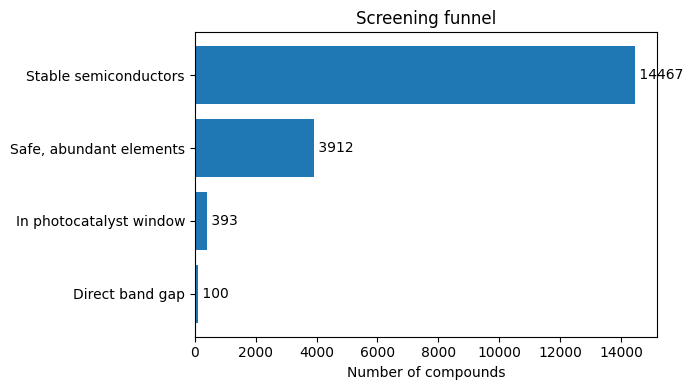

In [12]:
counts = {
    "Stable semiconductors": len(df),
    "Safe, abundant elements": int(df["safe_and_cheap"].sum()),
    "In photocatalyst window": int(df["true_hit"].sum()),
    "Direct band gap": int((df["true_hit"] & df["is_gap_direct"]).sum()),
}
fig, ax = plt.subplots(figsize=(7, 4))
labels, values = list(counts)[::-1], list(counts.values())[::-1]
ax.barh(labels, values)
for i, v in enumerate(values):
    ax.text(v, i, f" {v}", va="center")
ax.set_xlabel("Number of compounds")
ax.set_title("Screening funnel")
plt.tight_layout()
plt.savefig("fig3_funnel.png", dpi=200)
plt.show()

materials researchers already study for solar hydrogen

In [13]:
KNOWN = ["Fe2O3", "BiVO4", "Cu2O", "WO3", "CuBi2O4", "ZnV2O6",
         "TiO2"]   # TiO2 is a control: its gap is too wide
df[df["formula"].isin(KNOWN)][["formula", "band_gap", "predicted_gap",
                               "safe_and_cheap", "true_hit"]]

,formula,band_gap,predicted_gap,safe_and_cheap,true_hit
4011,Cu2O,0.5127,1.123866,True,False
13445,TiO2,2.0630,1.862147,True,False
14009,WO3,1.3530,2.308313,True,True


In [14]:
from google.colab import files
for f in ["fig1_parity.png", "fig2_importance.png", "fig3_funnel.png", "shortlist.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Top candidates, estimated raw-material cost (USD/kg, 2013 element prices):
    formula  band_gap  raw_cost_usd_per_kg
    FeP4O11      1.25               105.97
   Na2Zn2O3      1.25                53.14
Ti4(Ni5O8)3      1.25                16.57
  Ca11AlSb9      1.25                11.43
 Ca3(AlP2)2      1.25               127.09
  Ba(BiS2)2      1.25                15.55
       VCl2      1.26                12.00
K3Nb2CuSe12      1.26               198.22
NaAl3NiCl12      1.26                13.48
     WS9Cl4      1.26                14.38

Benchmarks:
formula                          note  raw_cost_usd_per_kg
    CdS               toxic benchmark                 2.18
 CuInS2      scarce-element benchmark               343.30
   TiO2         classic photocatalyst                10.05
  BiVO4 leading studied photocatalyst                21.11

Median cost of top candidates: $16.06/kg


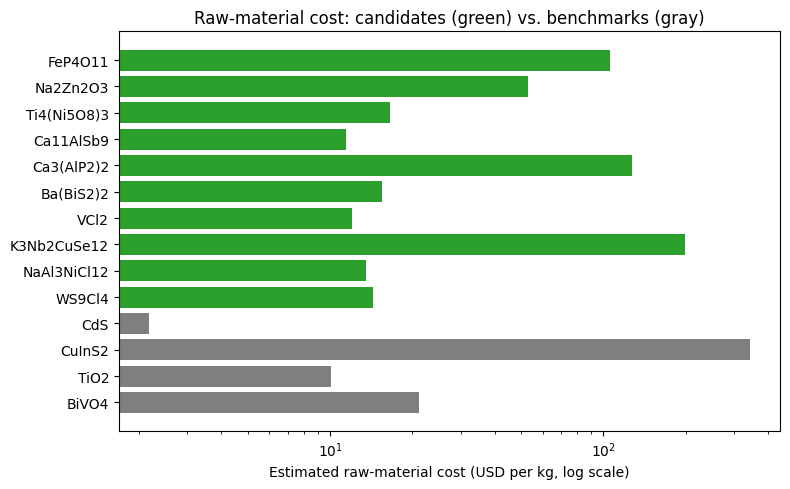

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.analysis.cost import CostAnalyzer, CostDBElements

warnings.filterwarnings("ignore")

# If Colab restarted, reload the shortlist from the file
try:
    shortlist
except NameError:
    shortlist = pd.read_csv("shortlist.csv")

cost_db = CostAnalyzer(CostDBElements())

def raw_cost_per_kg(formula):
    try:
        return cost_db.get_cost_per_kg(formula)
    except Exception:
        return float("nan")

top = shortlist.head(10).copy()
top["raw_cost_usd_per_kg"] = top["formula"].apply(raw_cost_per_kg)

benchmarks = pd.DataFrame({
    "formula": ["CdS", "CuInS2", "TiO2", "BiVO4"],
    "note": ["toxic benchmark", "scarce-element benchmark",
             "classic photocatalyst", "leading studied photocatalyst"],
})
benchmarks["raw_cost_usd_per_kg"] = benchmarks["formula"].apply(raw_cost_per_kg)

print("Top candidates, estimated raw-material cost (USD/kg, 2013 element prices):")
print(top[["formula", "band_gap", "raw_cost_usd_per_kg"]].round(2).to_string(index=False))
print("\nBenchmarks:")
print(benchmarks.round(2).to_string(index=False))
print(f"\nMedian cost of top candidates: ${top['raw_cost_usd_per_kg'].median():.2f}/kg")

plot_df = pd.concat([
    top[["formula", "raw_cost_usd_per_kg"]].assign(group="Your candidates"),
    benchmarks[["formula", "raw_cost_usd_per_kg"]].assign(group="Benchmarks"),
]).dropna()

colors = ["tab:green" if g == "Your candidates" else "tab:gray" for g in plot_df["group"]]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_df["formula"], plot_df["raw_cost_usd_per_kg"], color=colors)
ax.set_xscale("log")
ax.invert_yaxis()
ax.set_xlabel("Estimated raw-material cost (USD per kg, log scale)")
ax.set_title("Raw-material cost: candidates (green) vs. benchmarks (gray)")
plt.tight_layout()
plt.savefig("fig4_cost.png", dpi=200)
plt.show()

top.to_csv("shortlist_with_cost.csv", index=False)

from google.colab import files
files.download("fig4_cost.png")
files.download("shortlist_with_cost.csv")